# 01 · EDA & Preprocessing

Load the IMDB 50k reviews dataset, check class balance, clean the text, and save a cleaned copy to `data/imdb_clean.csv` for modeling in notebook 02.

In [1]:
import re
import string
from pathlib import Path

import matplotlib.pyplot as plt
import nltk
import pandas as pd
from nltk.corpus import stopwords

DATA_DIR = Path("../data")
IMG_DIR = Path("../images")
IMG_DIR.mkdir(exist_ok=True)

In [2]:
# Shared chart style
SURFACE, INK, INK_2, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
BLUE, ORANGE, RED = "#2a78d6", "#eb6834", "#e34948"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
    "font.size": 10, "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
})

## Load data

In [3]:
df = pd.read_csv(DATA_DIR / "IMDB-Dataset.csv")
df.head()

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [4]:
print(df.shape)
print("Duplicate reviews:", df["review"].duplicated().sum())

(50000, 2)
Duplicate reviews: 418


## Class balance

In [5]:
counts = df["sentiment"].value_counts().reindex(["negative", "positive"])
counts

sentiment
negative    25000
positive    25000
Name: count, dtype: int64

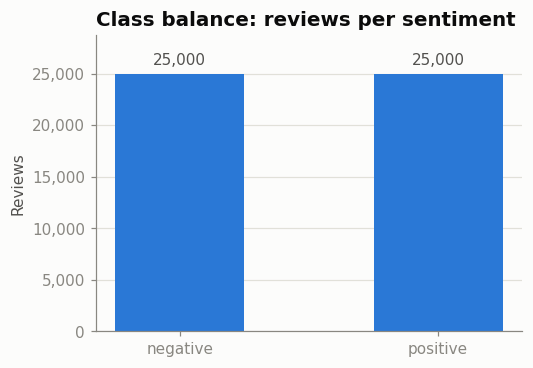

In [6]:
fig, ax = plt.subplots(figsize=(5, 3.5))
bars = ax.bar(counts.index, counts.values, color=BLUE, width=0.5)
ax.bar_label(bars, labels=[f"{v:,}" for v in counts.values], padding=4, color=INK_2)
ax.set_title("Class balance: reviews per sentiment")
ax.set_ylabel("Reviews")
ax.grid(axis="x", visible=False)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:,.0f}")
ax.set_ylim(0, counts.max() * 1.15)
fig.savefig(IMG_DIR / "class_balance.png")
plt.show()

## Text cleaning

Lowercase, strip HTML tags and URLs, remove punctuation, collapse whitespace. The raw `review` column is kept for error analysis; cleaned text goes in `clean_review`.

In [7]:
PUNCT_PATTERN = f"[{re.escape(string.punctuation)}]"

def clean(series):
    return (
        series
          .str.lower()
          .str.replace(r'<.*?>', ' ', regex=True)                  # HTML tags like <br />
          .str.replace(r'https?://\S+|www\.\S+', ' ', regex=True)  # URLs (before punctuation removal)
          .str.replace(PUNCT_PATTERN, '', regex=True)              # punctuation
          .str.replace(r'\s+', ' ', regex=True)                    # collapse extra whitespace
          .str.strip()
    )

df["clean_review"] = clean(df["review"])

In [8]:
nltk.download("stopwords", quiet=True)

stop_words = set(stopwords.words("english"))

# Keep negations, since they flip sentiment
negations = {"not", "no", "nor", "don", "didn", "doesn", "isn", "wasn",
             "weren", "aren", "couldn", "wouldn", "shouldn", "won", "hasn",
             "haven", "hadn", "mustn", "needn"}
stop_words = stop_words - negations

def remove_stopwords(text):
    return " ".join(word for word in text.split() if word not in stop_words)

df["clean_review"] = df["clean_review"].apply(remove_stopwords)

In [9]:
df.loc[0, "clean_review"]

'one reviewers mentioned watching 1 oz episode youll hooked right exactly happened first thing struck oz brutality unflinching scenes violence set right word go trust not show faint hearted timid show pulls no punches regards drugs sex violence hardcore classic use word called oz nickname given oswald maximum security state penitentary focuses mainly emerald city experimental section prison cells glass fronts face inwards privacy not high agenda em city home manyaryans muslims gangstas latinos christians italians irish moreso scuffles death stares dodgy dealings shady agreements never far away would say main appeal show due fact goes shows wouldnt dare forget pretty pictures painted mainstream audiences forget charm forget romanceoz doesnt mess around first episode ever saw struck nasty surreal couldnt say ready watched developed taste oz got accustomed high levels graphic violence not violence injustice crooked guards wholl sold nickel inmates wholl kill order get away well mannered m

## Save cleaned data

In [10]:
df[["review", "clean_review", "sentiment"]].to_csv(DATA_DIR / "imdb_clean.csv", index=False)